# 01. Hidden Markov Model

Seorang petugas bekerja di ruangan tanpa jendela. Ia tidak melihat cuaca di luar, tetapi setiap hari mencatat apakah rekannya membawa payung. Payung memberi petunjuk tentang hujan, tetapi bukan bukti pasti: orang bisa membawa payung saat tidak hujan atau tidak membawanya saat hujan.

**Hidden Markov Model (HMM)** memodelkan keadaan yang tidak diamati langsung melalui rangkaian pengamatan. Contoh payung dipakai dari awal sampai inferensi; bagian pelatihan menggunakan data sintetis dari model yang sama, bukan data cuaca nyata.

Setelah praktikum ini, Anda diharapkan mampu:

1. membedakan hidden state, observasi, probabilitas awal, transisi, dan emisi;
2. menghitung likelihood serta distribusi state dengan Forward dan Backward;
3. mencari jalur state dengan Viterbi dan membedakannya dari smoothing;
4. memprediksi state dan observasi berikutnya; serta
5. melatih HMM diskret dengan Baum-Welch dan membaca batas hasilnya.

Prasyarat: probabilitas bersyarat, aturan Bayes, perkalian matriks, dan Python dasar. Notebook dapat dijalankan sendiri tanpa notebook logika atau fuzzy.


## Setup

Jalankan sel berikut sebelum sel lain. Paket yang belum tersedia dipasang otomatis. Contoh HMM memakai library `hmmlearn`; dataset simulasi dibuat di notebook.

Untuk lokal, alternatifnya jalankan `python -m pip install -r requirements.txt` dari akar repo, lalu buka notebook melalui Jupyter Lab. Di Google Colab, unggah notebook dan jalankan sel dari atas ke bawah. Gunakan **Restart and Run All** sebelum mengumpulkan.

Environment siap jika keluaran terakhir berbunyi `Setup HMM siap.`.


In [1]:
import importlib.util
import importlib.metadata
import subprocess
import sys

required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "hmmlearn": "hmmlearn>=0.3.3"}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from hmmlearn import hmm

np.set_printoptions(precision=6, suppress=True)
print("Python:", sys.version.split()[0])
print("hmmlearn:", importlib.metadata.version("hmmlearn"))
print("Setup HMM siap.")


Python: 3.10.0
hmmlearn: 0.3.3
Setup HMM siap.


## 1.1 Dari Markov Chain ke Hidden Markov Model

### Penjelasan

Markov chain menggambarkan perubahan state dari satu waktu ke waktu berikutnya. Pada HMM, state tersebut tidak terlihat langsung; kita hanya mengamati keluaran yang dipengaruhi state.

Dalam contoh ini, $X_t$ adalah cuaca pada hari $t$ dan $O_t$ adalah pengamatan payung pada hari itu. HMM orde satu memakai dua asumsi:

$$P(X_t\mid X_{1:t-1})=P(X_t\mid X_{t-1}),$$

$$P(O_t\mid X_{1:t},O_{1:t-1})=P(O_t\mid X_t).$$

Asumsi pertama berarti state terakhir cukup untuk memodelkan transisi. Asumsi kedua berarti emisi hanya bergantung pada state saat ini. Parameter transisi dan emisi dalam notebook juga dianggap tetap sepanjang waktu (*time-homogeneous*).

| Komponen | Simbol | Isi contoh |
|---|---|---|
| Hidden state | $X_t$ | Hujan atau Tidak hujan |
| Observasi | $O_t$ | Payung atau Tanpa payung |
| Distribusi awal | $\pi_i=P(X_1=i)$ | Keyakinan sebelum pengamatan pertama |
| Matriks transisi | $A_{ij}=P(X_t=j\mid X_{t-1}=i)$ | Peluang perpindahan cuaca |
| Matriks emisi | $B_{ik}=P(O_t=k\mid X_t=i)$ | Peluang pengamatan untuk setiap cuaca |

Model ditulis $\lambda=(\pi,A,B)$. Baris $A$ menyatakan state asal, kolomnya state tujuan. Baris $B$ menyatakan state, kolomnya kategori observasi. Jumlah $\pi$ dan jumlah setiap baris $A$ serta $B$ harus satu.

Angka model mengikuti contoh *Umbrella World* pada implementasi AIMA [1]. Di notebook ini $\pi$ didefinisikan untuk $X_1$, sehingga observasi pertama langsung memakai $\pi B$ tanpa transisi awal. Beberapa referensi memakai prior $X_0$; pada konvensi itu perlu prediksi satu langkah sebelum observasi pertama.

### Contoh penerapan


In [2]:
state_names = ["Hujan", "Tidak hujan"]
observation_names = ["Payung", "Tanpa payung"]

pi = np.array([0.5, 0.5])
A = np.array([[0.7, 0.3],
              [0.3, 0.7]])
B = np.array([[0.9, 0.1],
              [0.2, 0.8]])

model = hmm.CategoricalHMM(n_components=2, n_features=2, algorithm="viterbi")
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

assert np.isclose(pi.sum(), 1.0)
assert np.allclose(A.sum(axis=1), 1.0)
assert np.allclose(B.sum(axis=1), 1.0)

display(pd.Series(pi, index=state_names, name="pi"))
display(pd.DataFrame(A, index=state_names, columns=state_names))
display(pd.DataFrame(B, index=state_names, columns=observation_names))


Hujan          0.5
Tidak hujan    0.5
Name: pi, dtype: float64

,Hujan,Tidak hujan
Hujan,0.7,0.3
Tidak hujan,0.3,0.7


,Payung,Tanpa payung
Hujan,0.9,0.1
Tidak hujan,0.2,0.8


Misalnya, $A_{0,1}=0{,}3$ berarti peluang besok tidak hujan jika hari ini hujan. Nilai $B_{0,0}=0{,}9$ berarti peluang membawa payung jika hujan, **bukan** peluang hujan jika terlihat payung. Dua probabilitas bersyarat itu berbeda.


## 1.2 Satu Pengamatan dan Aturan Bayes

### Penjelasan

Sebelum melihat payung, peluang hujan adalah 0,5. Setelah melihat payung, keyakinan diperbarui dengan Bayes:

$$P(X_1=i\mid O_1=k)=\frac{\pi_i B_{ik}}{\sum_j\pi_j B_{jk}}.$$

Untuk observasi Payung, bobot Hujan adalah $0{,}5\times0{,}9=0{,}45$, sedangkan bobot Tidak hujan adalah $0{,}5\times0{,}2=0{,}10$. Peluang pengamatannya $0{,}55$, sehingga posterior Hujan adalah $0{,}45/0{,}55\approx0{,}818182$.

Angka tersebut adalah probabilitas ketidakpastian state, bukan derajat keanggotaan fuzzy seperti pada modul Fuzzy Logic.

### Contoh penerapan


In [3]:
one_observation = np.array([[0]])
posterior = model.predict_proba(one_observation)[0]
evidence = np.exp(model.score(one_observation))
display(pd.Series(posterior, index=state_names, name="posterior setelah Payung"))
print(f"P(Payung) = {evidence:.6f}")
assert np.allclose(posterior, [9 / 11, 2 / 11])


Hujan          0.818182
Tidak hujan    0.181818
Name: posterior setelah Payung, dtype: float64

P(Payung) = 0.550000


Melihat payung menaikkan keyakinan hujan dari 0,5 menjadi sekitar 0,818. Hasilnya tidak menjadi satu karena orang juga bisa membawa payung ketika tidak hujan.


## 1.3 Likelihood Urutan dengan hmmlearn

### Penjelasan

Untuk satu jalur state $x_{1:T}$ dan observasi $o_{1:T}$, probabilitas gabungannya adalah

$$P(x_{1:T},o_{1:T}\mid\lambda)=\pi_{x_1}B_{x_1,o_1}\prod_{t=2}^{T}A_{x_{t-1},x_t}B_{x_t,o_t}.$$

State sebenarnya belum diketahui. Karena itu likelihood observasi harus menjumlahkan **semua** jalur state:

$$P(o_{1:T}\mid\lambda)=\sum_{x_{1:T}}P(x_{1:T},o_{1:T}\mid\lambda).$$

Dengan $N$ state dan $T$ waktu, enumerasi membutuhkan $N^T$ jalur. `model.score()` menghitung **log-likelihood** menggunakan algoritma Forward, tanpa mengenumerasi setiap jalur. Likelihood $P(O\mid\lambda)$ bukan probabilitas model benar $P(\lambda\mid O)$.

Tiga persoalan utama HMM [2] adalah evaluasi likelihood (Forward), decoding jalur state (Viterbi), dan pembelajaran parameter (Baum-Welch). Filtering serta smoothing menjawab distribusi state, bukan satu jalur terbaik.

### Contoh penerapan


In [4]:
observations = np.array([[0], [0], [1], [0], [0]])
short_observations = observations[:3]
short_log_likelihood = model.score(short_observations)
print("Observasi:", [observation_names[i] for i in short_observations[:, 0]])
print(f"Log-likelihood = {short_log_likelihood:.6f}")
print(f"Likelihood = {np.exp(short_log_likelihood):.6f}")
assert np.isclose(np.exp(short_log_likelihood), 0.120445)


Observasi: ['Payung', 'Payung', 'Tanpa payung']
Log-likelihood = -2.116562
Likelihood = 0.120445


Likelihood untuk Payung, Payung, Tanpa payung adalah 0,120445. `score()` mengembalikan log-likelihood; `np.exp()` mengubahnya menjadi likelihood.


## 1.4 Forward: Likelihood dan Filtering

### Penjelasan

Forward menggabungkan kontribusi jalur yang berakhir pada state yang sama:

$$\alpha_1(i)=\pi_i B_{i,o_1},$$

$$\alpha_t(j)=B_{j,o_t}\sum_i\alpha_{t-1}(i)A_{ij},\qquad P(o_{1:T}\mid\lambda)=\sum_j\alpha_T(j).$$

Dengan representasi vektor baris, prediksi state ditulis $f_{t-1}A$. Setelah dikalikan emisi dan dinormalisasi, diperoleh filtering $f_t(j)=P(X_t=j\mid o_{1:t})$.

`hmmlearn` menghitung Forward secara internal. Untuk mendapatkan filtering pada hari $t$, panggil `predict_proba()` hanya pada observasi sampai hari $t$, lalu ambil baris terakhir. Fungsi ini menghitung smoothing untuk prefix tersebut, yang pada hari terakhir sama dengan filtering. Cara ini menjalankan ulang inferensi untuk setiap prefix, sehingga cocok untuk demonstrasi urutan pendek, bukan implementasi streaming yang efisien.

### Contoh penerapan


In [5]:
filtered = np.vstack([
    model.predict_proba(observations[:t])[-1]
    for t in range(1, len(observations) + 1)
])
log_likelihood = model.score(observations)
filtering_table = pd.DataFrame(filtered, columns=state_names)
filtering_table.insert(0, "observasi", [observation_names[i] for i in observations[:, 0]])
filtering_table.index = np.arange(1, len(observations) + 1)
filtering_table.index.name = "hari"
display(filtering_table)
print(f"Log-likelihood lima hari = {log_likelihood:.6f}")
print(f"Likelihood lima hari = {np.exp(log_likelihood):.9f}")
assert np.allclose(filtered.sum(axis=1), 1.0)


,observasi,Hujan,Tidak hujan
hari,,,
1,Payung,0.818182,0.181818
2,Payung,0.883357,0.116643
3,Tanpa payung,0.190668,0.809332
4,Payung,0.730794,0.269206
5,Payung,0.867339,0.132661


Log-likelihood lima hari = -3.372502
Likelihood lima hari = 0.034303700


Dua hari pertama dengan payung menghasilkan filtering Hujan sekitar 0,818182 dan 0,883357. Pengamatan Tanpa payung pada hari ketiga menurunkannya menjadi sekitar 0,190668. Angka setiap baris hanya memakai observasi sampai hari tersebut, bukan observasi masa depan.

Input `CategoricalHMM` berbentuk dua dimensi `(jumlah_hari, 1)`; setiap baris menyimpan satu kategori observasi.


## 1.5 Backward dan Smoothing

### Penjelasan

Filtering hari pertama belum memakai informasi hari kedua dan seterusnya. Jika semua pengamatan sudah tersedia, kita bisa memperbarui keyakinan tentang masa lalu melalui smoothing:

$$\gamma_t(i)=P(X_t=i\mid o_{1:T}).$$

Backward merangkum bukti setelah waktu $t$:

$$\beta_T(i)=1,\qquad\beta_t(i)=\sum_j A_{ij}B_{j,o_{t+1}}\beta_{t+1}(j).$$

`model.predict_proba(observations)` menjalankan Forward-Backward dan mengembalikan distribusi smoothing untuk setiap hari. Ini berbeda dari pemanggilan pada setiap prefix di bagian filtering.

Smoothing berguna untuk analisis setelah rangkaian selesai. Untuk keputusan *real-time*, memakai observasi masa depan akan membocorkan informasi yang belum tersedia.

### Contoh penerapan


In [6]:
smoothed = model.predict_proba(observations)
comparison = pd.DataFrame({
    "observasi": [observation_names[i] for i in observations[:, 0]],
    "filtering P(Hujan)": filtered[:, 0],
    "smoothing P(Hujan)": smoothed[:, 0],
}, index=pd.Index(range(1, len(observations) + 1), name="hari"))
display(comparison)
assert np.allclose(smoothed.sum(axis=1), 1.0)
assert np.allclose(smoothed[-1], filtered[-1])


,observasi,filtering P(Hujan),smoothing P(Hujan)
hari,,,
1,Payung,0.818182,0.867339
2,Payung,0.883357,0.820419
3,Tanpa payung,0.190668,0.307484
4,Payung,0.730794,0.820419
5,Payung,0.867339,0.867339


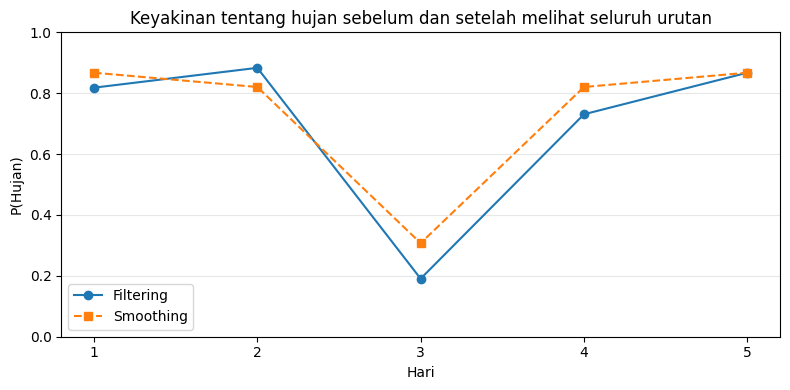

In [7]:
days = np.arange(1, len(observations) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(days, filtered[:, 0], "o-", label="Filtering")
ax.plot(days, smoothed[:, 0], "s--", label="Smoothing")
ax.set(xticks=days, ylim=(0, 1), xlabel="Hari", ylabel="P(Hujan)",
       title="Keyakinan tentang hujan sebelum dan setelah melihat seluruh urutan")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Smoothing bisa menaikkan atau menurunkan keyakinan masa lalu. Pada hari terakhir, smoothing sama dengan filtering karena tidak ada observasi setelahnya. Grafik membedakan dua jenis informasi yang tersedia, bukan membandingkan dua model yang berbeda.


## 1.6 Viterbi: Jalur State Paling Mungkin

### Penjelasan

Viterbi mencari **satu jalur bersama** yang memaksimalkan

$$x^*_{1:T}=\arg\max_{x_{1:T}}P(x_{1:T},o_{1:T}\mid\lambda).$$

Untuk observasi tetap dengan likelihood positif, jalur tersebut juga memaksimalkan $P(x_{1:T}\mid o_{1:T},\lambda)$ karena penyebutnya sama untuk semua jalur.

Berbeda dari Forward yang menjumlahkan semua kandidat, Viterbi mengambil nilai maksimum dan menyimpan asal state terbaik. Dalam domain log:

$$d_1(j)=\log\pi_j+\log B_{j,o_1},$$

$$d_t(j)=\log B_{j,o_t}+\max_i\{d_{t-1}(i)+\log A_{ij}\}.$$

Indeks yang menghasilkan maksimum disimpan sebagai *backpointer*. Penelusuran balik dimulai dari state terbaik pada hari terakhir. `model.decode(..., algorithm="viterbi")` mengembalikan skor log probabilitas gabungan dan jalurnya.

Mengambil state dengan posterior smoothing terbesar pada setiap waktu (*marginal MAP*) adalah tujuan berbeda. Hasilnya tidak selalu sama dengan Viterbi, bahkan bisa menyambung transisi yang tidak diizinkan ketika model memiliki transisi nol.

### Contoh penerapan


In [8]:
best_log_joint, best_path = model.decode(observations, algorithm="viterbi")
marginal_path = np.argmax(smoothed, axis=1)
display(pd.DataFrame({
    "observasi": [observation_names[i] for i in observations[:, 0]],
    "Viterbi": [state_names[i] for i in best_path],
    "marginal MAP": [state_names[i] for i in marginal_path],
}, index=pd.Index(days, name="hari")))
print(f"P(jalur terbaik, observasi) = {np.exp(best_log_joint):.9f}")
print(f"P(jalur terbaik | observasi) = {np.exp(best_log_joint - log_likelihood):.6f}")
assert best_log_joint <= log_likelihood + 1e-12


,observasi,Viterbi,marginal MAP
hari,,,
1,Payung,Hujan,Hujan
2,Payung,Hujan,Hujan
3,Tanpa payung,Tidak hujan,Tidak hujan
4,Payung,Hujan,Hujan
5,Payung,Hujan,Hujan


P(jalur terbaik, observasi) = 0.011573604
P(jalur terbaik | observasi) = 0.337386


Pada urutan lima hari ini, Viterbi menghasilkan Hujan, Hujan, Tidak hujan, Hujan, Hujan. Jalur marginal MAP kebetulan sama; kesamaan pada satu contoh tidak membuat dua tujuan optimasinya setara. Probabilitas gabungan jalur terbaik tidak boleh melebihi likelihood karena likelihood menjumlahkan seluruh jalur.


## 1.7 Prediksi State dan Observasi Berikutnya

### Penjelasan

Sesudah filtering hari terakhir, distribusi cuaca besok adalah

$$P(X_{T+1}\mid o_{1:T})=f_T A.$$

Prediksi $h$ langkah tanpa observasi baru adalah $f_T A^h$. Untuk memprediksi payung besok, seluruh kemungkinan state perlu dimarginalkan:

$$P(O_{T+1}\mid o_{1:T})=(f_T A)B.$$

Prediksi ini berbeda dari filtering besok: filtering baru bisa dilakukan setelah observasi besok tersedia. `hmmlearn` tidak menyediakan metode publik untuk distribusi prediksi ke depan; contoh memakai posterior dari `predict_proba()` dan matriks model dengan NumPy.

### Contoh penerapan


In [9]:
next_state = smoothed[-1] @ model.transmat_
next_observation = next_state @ model.emissionprob_
three_days_ahead = smoothed[-1] @ np.linalg.matrix_power(model.transmat_, 3)

display(pd.DataFrame({
    "besok": next_state,
    "tiga hari lagi, tanpa observasi baru": three_days_ahead,
}, index=state_names))
display(pd.Series(next_observation, index=observation_names, name="prediksi observasi besok"))
assert np.isclose(next_state.sum(), 1.0)
assert np.isclose(next_observation.sum(), 1.0)


,besok,"tiga hari lagi, tanpa observasi baru"
Hujan,0.646936,0.52351
Tidak hujan,0.353064,0.47649


Payung          0.652855
Tanpa payung    0.347145
Name: prediksi observasi besok, dtype: float64

Transisi berulang tanpa bukti baru membuat prediksi cuaca mendekati distribusi stasioner [0,5; 0,5] untuk matriks transisi contoh ini. Sifat tersebut bukan aturan bahwa semua HMM selalu menuju peluang sama besar.


## 1.8 Baum-Welch: Belajar dari Observasi Tanpa Label State

### Penjelasan

Pada bagian sebelumnya, $\pi,A,B$ sudah diketahui. Dalam pembelajaran tanpa label, kita hanya memiliki urutan observasi. Baum-Welch adalah algoritma *Expectation-Maximization* (EM) untuk memperbarui parameter HMM [2]. Kita menetapkan jumlah state terlebih dahulu.

Pada **E-step**, Forward-Backward menghitung $\gamma_t(i)$ serta posterior transisi

$$\xi_t(i,j)=P(X_t=i,X_{t+1}=j\mid o_{1:T},\lambda)\propto f_t(i)A_{ij}B_{j,o_{t+1}}\widetilde\beta_{t+1}(j).$$

Normalisasi $\xi_t$ dilakukan terhadap seluruh pasangan $(i,j)$. Pada **M-step**, hitungan harapan tersebut menjadi parameter baru. Untuk $R$ urutan independen dengan panjang $T_r$:

$$\pi'_i=\frac{1}{R}\sum_r\gamma^{(r)}_1(i),$$

$$A'_{ij}=\frac{\sum_r\sum_{t=1}^{T_r-1}\xi^{(r)}_t(i,j)}{\sum_r\sum_{t=1}^{T_r-1}\gamma^{(r)}_t(i)},$$

$$B'_{ik}=\frac{\sum_r\sum_{t=1}^{T_r}\gamma^{(r)}_t(i)\,\mathbf{1}[o^{(r)}_t=k]}{\sum_r\sum_{t=1}^{T_r}\gamma^{(r)}_t(i)}.$$

Jangan membuat transisi dari akhir satu urutan ke awal urutan lain. Tiap urutan dimulai lagi dari $\pi$.

Contoh memakai 30 urutan latih dan 10 urutan uji, masing-masing 40 hari, yang disimulasikan secara terpisah. Angka ini adalah rancangan eksperimen, bukan ukuran dataset cuaca nyata. State simulasi tidak dipakai saat pelatihan. Parameter awal dibuat positif agar E-step memiliki dukungan probabilitas untuk semua state dan kategori.

`model.sample()` membuat tiap urutan secara independen. `fit(X, lengths)` menerima seluruh observasi yang digabung, dengan `lengths` sebagai batas setiap urutan. `init_params=""` mempertahankan parameter awal yang kita tentukan; `params="ste"` mengizinkan ketiganya dilatih. `monitor_.history` mencatat likelihood yang dievaluasi selama pelatihan. Nilai akhir model dihitung lagi dengan `score()`.

### Contoh penerapan


In [10]:
rng = np.random.RandomState(42)
train_sequences = [model.sample(40, random_state=rng)[0] for _ in range(30)]
test_sequences = [model.sample(40, random_state=rng)[0] for _ in range(10)]
train_X = np.concatenate(train_sequences)
test_X = np.concatenate(test_sequences)
train_lengths = [len(sequence) for sequence in train_sequences]
test_lengths = [len(sequence) for sequence in test_sequences]

initial_pi = np.array([0.6, 0.4])
initial_A = np.array([[0.6, 0.4], [0.4, 0.6]])
initial_B = np.array([[0.6, 0.4], [0.4, 0.6]])
trained = hmm.CategoricalHMM(
    n_components=2, n_features=2, init_params="", params="ste",
    n_iter=30, tol=1e-6, random_state=42,
)
trained.startprob_ = initial_pi.copy()
trained.transmat_ = initial_A.copy()
trained.emissionprob_ = initial_B.copy()
train_before = trained.score(train_X, train_lengths)
test_before = trained.score(test_X, test_lengths) / len(test_X)
trained.fit(train_X, train_lengths)
history = np.asarray(trained.monitor_.history)

display(pd.Series(trained.startprob_, index=["State 0", "State 1"], name="pi hasil belajar"))
display(pd.DataFrame(trained.transmat_, index=["State 0", "State 1"], columns=["State 0", "State 1"]))
display(pd.DataFrame(trained.emissionprob_, index=["State 0", "State 1"], columns=observation_names))
display(pd.DataFrame({
    "model": ["awal", "hasil Baum-Welch"],
    "log-likelihood latih": [train_before, trained.score(train_X, train_lengths)],
    "log-likelihood uji per observasi": [test_before, trained.score(test_X, test_lengths) / len(test_X)],
}))
print("Iterasi:", trained.monitor_.iter)
assert np.allclose(trained.transmat_.sum(axis=1), 1.0)
assert np.allclose(trained.emissionprob_.sum(axis=1), 1.0)


State 0    0.418039
State 1    0.581961
Name: pi hasil belajar, dtype: float64

,State 0,State 1
State 0,0.722849,0.277151
State 1,0.284059,0.715941


,Payung,Tanpa payung
State 0,0.867914,0.132086
State 1,0.242159,0.757841


,model,log-likelihood latih,log-likelihood uji per observasi
0,awal,-829.935600,-0.691797
1,hasil Baum-Welch,-804.706048,-0.687068


Iterasi: 30


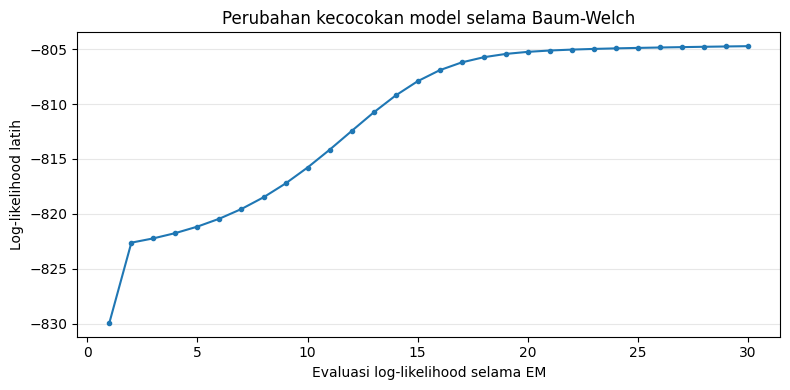

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(history) + 1), history, "o-", markersize=3)
ax.set(xlabel="Evaluasi log-likelihood selama EM", ylabel="Log-likelihood latih",
       title="Perubahan kecocokan model selama Baum-Welch")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Log-likelihood yang lebih besar berarti observasi lebih cocok dengan model. Pada EM dengan pembaruan eksak, likelihood latih tidak menurun secara teori; perhitungan numerik bisa memberi selisih kecil. Kurva mendatar bukan bukti optimum global. Satu inisialisasi di sini memperagakan proses, bukan pencarian model terbaik.

Evaluasi uji memakai urutan yang tidak dipakai E-step atau M-step. Nilai uji tidak dijamin membaik hanya karena likelihood latih meningkat. Saat membandingkan urutan dengan panjang berbeda, gunakan log-likelihood per observasi dan tetap perhatikan jenis data yang dibandingkan.

State 0 dan State 1 belum otomatis berarti Hujan dan Tidak hujan. Label state dapat dipertukarkan bersama baris/kolom parameter tanpa mengubah likelihood (*label switching*). Interpretasi harus melihat emisi atau informasi eksternal. Parameter hasil belajar juga tidak harus tepat sama dengan parameter pembangkit karena data terbatas dan EM bisa mencapai optimum lokal. Probabilitas awal hanya mendapat satu kontribusi per urutan, bukan per hari, sehingga estimasinya memakai lebih sedikit informasi daripada emisi.


## 1.9 Stabilitas Numerik dan Batas Model

### Penjelasan

Forward tanpa scaling mengalikan probabilitas berulang kali. Pada urutan panjang, likelihood dapat terlalu kecil untuk direpresentasikan sebagai `float`. `model.score()` mengembalikan log-likelihood agar nilainya tetap dapat digunakan; mengubahnya kembali dengan `np.exp()` masih bisa menghasilkan nol karena underflow.

Likelihood nol secara matematis berarti semua jalur untuk observasi tersebut mustahil menurut model. Dalam keadaan itu posterior $P(X\mid O)$ tidak terdefinisi. Perilaku API untuk urutan mustahil dapat berbeda menurut algoritma numerik; jangan menganggap distribusi posterior valid tanpa memeriksa likelihood.

HMM diskret contoh ini juga punya batas: dependensi state hanya satu langkah, emisi hanya memakai state saat ini, dan parameter dianggap tetap. HMM Gaussian memakai distribusi kontinu untuk emisi; matriks kategori $B$ pada notebook ini tidak langsung cocok untuk nilai kontinu seperti suhu.

### Contoh penerapan


In [12]:
long_observations = np.tile(observations, (400, 1))
long_log_likelihood = model.score(long_observations)
print(f"Log-likelihood: {long_log_likelihood:.6f}")
print("Likelihood setelah exp:", np.exp(long_log_likelihood))
assert np.isfinite(long_log_likelihood)


Log-likelihood: -1270.959802
Likelihood setelah exp: 0.0


Log-likelihood tetap berhingga. `np.exp()` dapat menghasilkan nol akibat underflow; ini tidak berarti observasi secara matematis mustahil.


## Ringkasan dan Referensi

| Tujuan | Keluaran | Informasi yang dipakai |
|---|---|---|
| Evaluasi | $P(o_{1:T}\mid\lambda)$ atau log-nya | Seluruh observasi, parameter diketahui |
| Filtering | $P(X_t\mid o_{1:t})$ | Observasi sampai waktu $t$ |
| Smoothing | $P(X_t\mid o_{1:T})$ | Seluruh observasi, termasuk setelah $t$ |
| Decoding Viterbi | Satu jalur $x^*_{1:T}$ | Seluruh observasi dan peluang transisi |
| Prediksi | $P(X_{T+h}\mid o_{1:T})$ | Bukti saat ini, tanpa observasi masa depan |
| Learning Baum-Welch | Estimasi $\pi,A,B$ | Urutan observasi tanpa label state |

Rujukan konsep dan parameter:

1. [AIMA Java, `HMMExampleFactory.java`](https://github.com/aimacode/aima-java/blob/AIMA3e/aima-core/src/main/java/aima/core/probability/example/HMMExampleFactory.java): sumber parameter contoh *Umbrella World*. Notebook menggunakan `hmmlearn`, bukan memanggil kode Java.
2. [Dokumentasi hmmlearn, Tutorial](https://hmmlearn.readthedocs.io/en/stable/tutorial.html): komponen HMM, tiga persoalan utama, Viterbi, EM/Baum-Welch, urutan independen, serta risiko optimum lokal dan pertukaran label. Untuk satu kategori per waktu, API library yang sesuai adalah `CategoricalHMM`; `MultinomialHMM` bukan pengganti langsung untuk format tersebut.

Pola penyusunan mengikuti `PANDUAN.md`, notebook `logics/02 - Entailment & Inference.ipynb`, dan `Fuzzy Logic/01 - Dasar Fuzzy dan Fuzzifikasi.ipynb`: setup, penjelasan, contoh yang berjalan, pembacaan hasil, lalu latihan. Belum ada slide HMM dalam folder materi repo yang ditinjau, sehingga angka contoh dirujuk ke AIMA dan eksperimen pelatihan diberi label sintetis.


# Latihan Soal

Semua soal memakai fungsi dan parameter dari notebook ini, kecuali jika soal menyebut perubahan. Isi sel jawaban yang tersedia. Pembahasan dapat dibuka setelah mencoba. Sel jawaban sengaja kosong, bukan bagian implementasi materi yang belum selesai.

## Soal 1: Memahami state dan emisi

Dalam sistem pengenalan aktivitas, sensor hanya mencatat kategori gerakan Rendah atau Tinggi, sedangkan aktivitas sebenarnya Duduk atau Berjalan tidak diamati. Tentukan hidden state dan observasinya. Jelaskan mengapa peluang Gerakan tinggi jika Berjalan tidak sama dengan peluang Berjalan jika Gerakan tinggi. Asumsi HMM mana yang bisa gagal jika gerakan juga bergantung pada aktivitas dua waktu sebelumnya?


<details>
<summary>Klik untuk melihat pembahasan Soal 1</summary>

Hidden state adalah Duduk/Berjalan; observasi adalah kategori gerakan Rendah/Tinggi. Probabilitas emisi mengondisikan pada aktivitas, sedangkan probabilitas aktivitas setelah melihat sensor memerlukan Bayes dan prior aktivitas. Asumsi emisi hanya bergantung pada state saat ini bisa gagal jika aktivitas yang lebih lama masih memengaruhi sensor setelah state saat ini diketahui. Jika transisi aktivitas juga bergantung pada lebih dari state terakhir, asumsi Markov orde satu ikut gagal.

</details>


## Soal 2: Menghitung filtering secara manual dan dengan kode

Ganti observasi menjadi Tanpa payung, Payung (`np.array([[1], [0]])`). Hitung posterior Hujan setelah hari pertama, prediksi cuaca sebelum hari kedua, dan posterior setelah observasi kedua. Cocokkan dengan `model.predict_proba()` pada setiap prefix dan periksa likelihood dengan `model.score()`.


<details>
<summary>Klik untuk melihat pembahasan Soal 2</summary>

Bobot hari pertama [0,05; 0,40], sehingga posteriornya [1/9; 8/9]. Prediksi sebelum observasi kedua [0,344444; 0,655556]. Setelah dikalikan emisi Payung, bobotnya [0,31; 0,131111], sehingga posterior Hujan sekitar 0,702771. Likelihood dua pengamatan adalah 0,1985.

```python
answer_observations = np.array([[1], [0]])
answer_filtered = np.vstack([
    model.predict_proba(answer_observations[:t])[-1]
    for t in range(1, len(answer_observations) + 1)
])
display(pd.DataFrame(answer_filtered, columns=state_names))
print("Prediksi sebelum hari kedua:", answer_filtered[0] @ model.transmat_)
assert np.isclose(answer_filtered[0, 0], 1 / 9)
assert np.isclose(answer_filtered[1, 0], 279 / 397)
assert np.isclose(np.exp(model.score(answer_observations)), 0.1985)
```

</details>


## Soal 3: Viterbi dan likelihood

Gunakan `np.array([[0], [1], [0], [1]])`. Cari jalur dan probabilitas gabungan terbaik dengan `model.decode(..., algorithm="viterbi")`, lalu hitung likelihood dengan `model.score()`. Jelaskan mengapa keduanya berbeda.


<details>
<summary>Klik untuk melihat pembahasan Soal 3</summary>

```python
answer_observations = np.array([[0], [1], [0], [1]])
answer_score, answer_path = model.decode(answer_observations, algorithm="viterbi")
answer_likelihood = np.exp(model.score(answer_observations))
print("Jalur:", [state_names[i] for i in answer_path])
print("Probabilitas gabungan maksimum:", np.exp(answer_score))
print("Likelihood:", answer_likelihood)
assert np.exp(answer_score) < answer_likelihood
```

Viterbi mengambil maksimum, sedangkan likelihood menjumlahkan probabilitas semua jalur. Untuk model ini semua jalur memiliki probabilitas positif, sehingga likelihood lebih besar daripada probabilitas gabungan jalur terbaik.

</details>


## Soal 4: Sensor yang tidak informatif

Buat kedua baris emisi sama, `np.array([[0.5, 0.5], [0.5, 0.5]])`, tanpa mengubah prior atau transisi. Jalankan filtering dan smoothing untuk urutan lima hari. Prediksi hasilnya sebelum menjalankan kode. Apakah mengganti kategori Payung menjadi Tanpa payung mengubah keyakinan tentang cuaca?


<details>
<summary>Klik untuk melihat pembahasan Soal 4</summary>

Pengamatan tidak membedakan state karena likelihood pengamatan sama pada kedua state. Pada prior [0,5; 0,5] dan transisi simetris contoh ini, filtering dan smoothing tetap [0,5; 0,5] untuk setiap hari. Mengganti kategori observasi tidak mengubah keyakinan cuaca. Dengan prior atau transisi lain, keyakinan masih dapat berubah karena dinamika state, tetapi bukan karena bukti dari sensor identik ini.

```python
uninformative = hmm.CategoricalHMM(n_components=2, n_features=2)
uninformative.startprob_ = pi.copy()
uninformative.transmat_ = A.copy()
uninformative.emissionprob_ = np.full((2, 2), 0.5)
answer_filtered = np.vstack([
    uninformative.predict_proba(observations[:t])[-1]
    for t in range(1, len(observations) + 1)
])
answer_smoothed = uninformative.predict_proba(observations)
assert np.allclose(answer_filtered, 0.5)
assert np.allclose(answer_smoothed, 0.5)
assert np.isclose(uninformative.score(observations), len(observations) * np.log(0.5))
```

</details>


## Soal 5: Menganalisis hasil belajar

Ulangi Baum-Welch dengan `initial_B = np.array([[0.8, 0.2], [0.3, 0.7]])` menggunakan data latih dan uji yang sama. Bandingkan likelihood akhir pada data latih dan uji dengan hasil sebelumnya. Jelaskan mengapa state bernomor sama tidak otomatis memiliki makna sama pada dua hasil pelatihan. Apakah likelihood latih lebih besar menjamin prediksi pada data baru lebih baik?


<details>
<summary>Klik untuk melihat pembahasan Soal 5</summary>

```python
alternative = hmm.CategoricalHMM(
    n_components=2, n_features=2, init_params="", params="ste",
    n_iter=30, tol=1e-6, random_state=42,
)
alternative.startprob_ = initial_pi.copy()
alternative.transmat_ = initial_A.copy()
alternative.emissionprob_ = np.array([[0.8, 0.2], [0.3, 0.7]])
alternative.fit(train_X, train_lengths)
display(pd.DataFrame({
    "inisialisasi": ["contoh awal", "alternatif"],
    "log-likelihood latih": [
        trained.score(train_X, train_lengths), alternative.score(train_X, train_lengths)
    ],
    "log-likelihood uji per observasi": [
        trained.score(test_X, test_lengths) / len(test_X),
        alternative.score(test_X, test_lengths) / len(test_X),
    ],
}))
```

Inisialisasi dapat menghasilkan parameter atau optimum lokal berbeda. Bandingkan distribusi emisi untuk menyelaraskan makna state, bukan hanya nomor state. Likelihood latih yang lebih tinggi tidak menjamin generalisasi. Data uji pada latihan ini membantu menjelaskan perbedaan tersebut; pada pemilihan model sungguhan, gunakan data validasi untuk memilih inisialisasi dan simpan data uji untuk evaluasi akhir.

</details>
